# COMP532 Assignment 2: LunarLander Double DQN

This notebook implements the main Assignment 2 programming task: a deep reinforcement learning agent
for Gymnasium LunarLander. The implementation uses Double DQN with a target network, replay buffer,
epsilon-greedy exploration, and PyTorch.

The default training configuration is exactly 1000 episodes so the reward curve covers the required
episode range. Training is intentionally not rendered; rendering is only used after training to
generate the demonstration GIF.

The notebook is organised as: dependencies, configuration, environment setup, model/replay buffer,
Double DQN agent, training, plots, greedy evaluation, GIF generation, and a final summary.

## Dependencies

The expected packages are listed in 'requirements.txt'.

In [ ]:
from __future__ import annotations

import json
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Optional

import gymnasium as gym
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import trange

print(f"Gymnasium: {gym.__version__}")
print(f"PyTorch: {torch.__version__}")

## Configuration

The hyperparameters are deliberately modest to keep runtime low, replay updates every
four environment steps, and no rendering during training.

Raw Gymnasium reward remains the main reported metric. The optional shaping parameters below only
affect the replay reward used for learning, and are logged separately for transparency.

In [2]:
@dataclass
class Config:
    """Hyperparameters and output locations for one complete LunarLander run."""

    seed: int = 532
    env_id: str = "LunarLander-v3"
    fallback_env_id: str = "LunarLander-v2"
    episodes: int = 1000
    max_steps_per_episode: int = 1000
    gamma: float = 0.99
    learning_rate: float = 5e-4
    batch_size: int = 128
    replay_capacity: int = 100_000
    min_replay_size: int = 1_000
    train_every: int = 4
    tau: float = 0.005
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_episodes: int = 850
    hidden_sizes: tuple[int, int] = (128, 128)
    grad_clip_norm: float = 10.0
    rolling_window: int = 100
    eval_episodes: int = 10
    # Mild training-only reward shaping. Raw Gymnasium rewards are still logged, plotted, and used for evaluation.
    shaping_center_penalty: float = 0.30
    shaping_low_altitude_center_penalty: float = 2.50
    shaping_horizontal_velocity_penalty: float = 0.20
    shaping_hover_penalty: float = 0.05
    shaping_low_altitude_threshold: float = 0.18
    shaping_center_touchdown_bonus: float = 8.0
    shaping_center_threshold: float = 0.08
    shaping_controlled_descent_bonus: float = 0.03
    demo_max_steps: int = 1000
    demo_candidate_count: int = 40
    demo_seed_offset: int = 20_000
    demo_center_weight: float = 250.0
    demo_step_weight: float = 0.05
    demo_success_bonus: float = 25.0
    gif_fps: int = 30
    output_dir: Path = Path("outputs")
    model_dir: Path = Path("models")
    video_dir: Path = Path("videos")

BASE_DIR = Path(".")
cfg = Config(
    output_dir=BASE_DIR / "outputs",
    model_dir=BASE_DIR / "models",
    video_dir=BASE_DIR / "videos",
)
for directory in [cfg.output_dir, cfg.model_dir, cfg.video_dir]:
    directory.mkdir(parents=True, exist_ok=True)

cfg

Config(seed=532, env_id='LunarLander-v3', fallback_env_id='LunarLander-v2', episodes=1000, max_steps_per_episode=1000, gamma=0.99, learning_rate=0.0005, batch_size=128, replay_capacity=100000, min_replay_size=1000, train_every=4, tau=0.005, epsilon_start=1.0, epsilon_end=0.05, epsilon_decay_episodes=850, hidden_sizes=(128, 128), grad_clip_norm=10.0, rolling_window=100, eval_episodes=10, shaping_center_penalty=0.3, shaping_low_altitude_center_penalty=2.5, shaping_horizontal_velocity_penalty=0.2, shaping_hover_penalty=0.05, shaping_low_altitude_threshold=0.18, shaping_center_touchdown_bonus=8.0, shaping_center_threshold=0.08, shaping_controlled_descent_bonus=0.03, demo_max_steps=1000, demo_candidate_count=40, demo_seed_offset=20000, demo_center_weight=250.0, demo_step_weight=0.05, demo_success_bonus=25.0, gif_fps=30, output_dir=PosixPath('outputs'), model_dir=PosixPath('models'), video_dir=PosixPath('videos'))

## Device and Reproducibility

The notebook uses MPS when available, otherwise CPU. Gymnasium environment dynamics still run on
CPU; only neural-network updates use the selected PyTorch device.

In [3]:
def select_device() -> torch.device:
    """Use Apple MPS when available; otherwise use CPU for portable execution."""
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

device = select_device()
print(f"Using device: {device}")

def set_seed(seed: int) -> None:
    """Seed Python, NumPy, and PyTorch so runs are as reproducible as practical."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

set_seed(cfg.seed)

Using device: mps


## Environment Helper

The helper prefers `LunarLander-v3`, with a fallback to `LunarLander-v2` for older installations.

In [4]:
def make_lunar_env(render_mode: Optional[str] = None, seed: Optional[int] = None) -> tuple[gym.Env, str]:
    """Create LunarLander-v3, falling back to v2 only for older Gymnasium installs."""
    last_error: Optional[Exception] = None
    for env_id in [cfg.env_id, cfg.fallback_env_id]:
        try:
            env = gym.make(env_id, render_mode=render_mode)
            if seed is not None:
                env.reset(seed=seed)
                env.action_space.seed(seed)
            return env, env_id
        except Exception as exc:
            last_error = exc
    raise RuntimeError("Could not create a LunarLander environment") from last_error

env, active_env_id = make_lunar_env(seed=cfg.seed)
state_dim = int(np.prod(env.observation_space.shape))
action_dim = int(env.action_space.n)
print(f"Environment: {active_env_id}")
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")
env.close()

Environment: LunarLander-v3
Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action space: Discrete(4)


## Q-Network and Replay Buffer

The Q-network estimates one action value per discrete LunarLander action. The replay buffer stores
transitions in NumPy arrays to avoid slow per-sample object handling during training.

In [5]:
class QNetwork(nn.Module):
    """Small MLP mapping an 8-dimensional state to one Q-value per action."""

    def __init__(self, state_dim: int, action_dim: int, hidden_sizes: tuple[int, int]):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_sizes[0]),
            nn.ReLU(),
            nn.Linear(hidden_sizes[0], hidden_sizes[1]),
            nn.ReLU(),
            nn.Linear(hidden_sizes[1], action_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class ReplayBuffer:
    """Fixed-size circular replay buffer backed by NumPy arrays for efficient sampling."""

    def __init__(self, capacity: int, state_dim: int, seed: int):
        self.capacity = capacity
        self.rng = np.random.default_rng(seed)
        self.states = np.zeros((capacity, state_dim), dtype=np.float32)
        self.actions = np.zeros((capacity, 1), dtype=np.int64)
        self.rewards = np.zeros((capacity, 1), dtype=np.float32)
        self.next_states = np.zeros((capacity, state_dim), dtype=np.float32)
        self.dones = np.zeros((capacity, 1), dtype=np.float32)
        self.position = 0
        self.size = 0

    def add(self, state, action: int, reward: float, next_state, done: bool) -> None:
        idx = self.position
        self.states[idx] = np.asarray(state, dtype=np.float32)
        self.actions[idx, 0] = action
        self.rewards[idx, 0] = reward
        self.next_states[idx] = np.asarray(next_state, dtype=np.float32)
        self.dones[idx, 0] = float(done)
        self.position = (self.position + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int):
        """Return a random minibatch of transitions as NumPy arrays."""
        indices = self.rng.integers(0, self.size, size=batch_size)
        return (
            self.states[indices],
            self.actions[indices],
            self.rewards[indices],
            self.next_states[indices],
            self.dones[indices],
        )

    def __len__(self) -> int:
        """Current number of stored transitions."""
        return self.size

## Double DQN Agent

Double DQN reduces overestimation bias by using the online network to select the next action and the
target network to evaluate that selected action. Terminal transitions are masked with `(1 - done)`.

In [6]:
class DoubleDQNAgent:
    """Double DQN agent with online/target networks and experience replay."""

    def __init__(self, state_dim: int, action_dim: int, cfg: Config, device: torch.device):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.cfg = cfg
        self.device = device
        self.online = QNetwork(state_dim, action_dim, cfg.hidden_sizes).to(device)
        self.target = QNetwork(state_dim, action_dim, cfg.hidden_sizes).to(device)
        self.target.load_state_dict(self.online.state_dict())
        self.target.eval()
        for param in self.target.parameters():
            param.requires_grad_(False)
        self.optimizer = optim.Adam(self.online.parameters(), lr=cfg.learning_rate)
        self.memory = ReplayBuffer(cfg.replay_capacity, state_dim, cfg.seed)
        self.update_count = 0

    def epsilon_by_episode(self, episode: int) -> float:
        """Linearly decay epsilon from exploration-heavy to mostly greedy behaviour."""
        fraction = min(episode / max(1, self.cfg.epsilon_decay_episodes), 1.0)
        return self.cfg.epsilon_start + fraction * (self.cfg.epsilon_end - self.cfg.epsilon_start)

    def act(self, state: np.ndarray, epsilon: float = 0.0) -> int:
        """Select an action with epsilon-greedy exploration."""
        if random.random() < epsilon:
            return random.randrange(self.action_dim)
        state_tensor = torch.as_tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
        with torch.no_grad():
            q_values = self.online(state_tensor)
        return int(q_values.argmax(dim=1).item())

    def learn(self) -> Optional[float]:
        """Run one Double DQN minibatch update and return the scalar loss."""
        if len(self.memory) < max(self.cfg.min_replay_size, self.cfg.batch_size):
            return None

        states, actions, rewards, next_states, dones = self.memory.sample(self.cfg.batch_size)
        states_t = torch.as_tensor(states, dtype=torch.float32, device=self.device)
        actions_t = torch.as_tensor(actions, dtype=torch.long, device=self.device)
        rewards_t = torch.as_tensor(rewards, dtype=torch.float32, device=self.device)
        next_states_t = torch.as_tensor(next_states, dtype=torch.float32, device=self.device)
        dones_t = torch.as_tensor(dones, dtype=torch.float32, device=self.device)

        q_expected = self.online(states_t).gather(1, actions_t)

        with torch.no_grad():
            next_actions = self.online(next_states_t).argmax(dim=1, keepdim=True)
            next_q_values = self.target(next_states_t).gather(1, next_actions)
            q_targets = rewards_t + self.cfg.gamma * next_q_values * (1.0 - dones_t)

        loss = F.smooth_l1_loss(q_expected, q_targets)
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.online.parameters(), self.cfg.grad_clip_norm)
        self.optimizer.step()
        self.soft_update()
        self.update_count += 1
        return float(loss.item())

    def soft_update(self) -> None:
        """Move target-network weights slowly toward the online-network weights."""
        with torch.no_grad():
            for target_param, online_param in zip(self.target.parameters(), self.online.parameters()):
                target_param.data.mul_(1.0 - self.cfg.tau)
                target_param.data.add_(self.cfg.tau * online_param.data)

    def save(self, path: Path, metadata: dict) -> None:
        """Save model, optimiser, config, and run metadata to a checkpoint."""
        config_dict = asdict(self.cfg)
        for key in ["output_dir", "model_dir", "video_dir"]:
            config_dict[key] = str(config_dict[key])
        payload = {
            "model_state_dict": self.online.state_dict(),
            "target_state_dict": self.target.state_dict(),
            "optimizer_state_dict": self.optimizer.state_dict(),
            "config": config_dict,
            "metadata": metadata,
        }
        torch.save(payload, path)

    def load(self, path: Path) -> dict:
        """Load a checkpoint produced by this notebook and return its metadata."""
        payload = torch.load(path, map_location=self.device, weights_only=False)
        self.online.load_state_dict(payload["model_state_dict"])
        self.target.load_state_dict(payload["target_state_dict"])
        self.optimizer.load_state_dict(payload["optimizer_state_dict"])
        return payload.get("metadata", {})

## Training Loop

Run this cell for the final 1000-episode training trace. The agent learns from a mildly shaped
reward that favours centred, low-hover landings, but the notebook still logs and plots the raw
Gymnasium reward required. Rendering is deliberately avoided during training.

In [7]:
def moving_average(values: list[float], window: int) -> np.ndarray:
    """Compute a rolling mean with sensible values from episode 1 onward."""
    series = pd.Series(values, dtype="float64")
    return series.rolling(window=window, min_periods=1).mean().to_numpy()


def shaped_lunar_reward(raw_reward: float, next_state: np.ndarray, done: bool, cfg: Config) -> float:
    """Return the shaped replay reward while preserving raw reward for reporting."""
    x = float(next_state[0])
    y = float(next_state[1])
    vx = float(next_state[2])
    vy = float(next_state[3])
    angle = float(next_state[4])
    left_contact = bool(next_state[6])
    right_contact = bool(next_state[7])
    low_altitude = y < cfg.shaping_low_altitude_threshold
    no_contact = not left_contact and not right_contact

    shaped = float(raw_reward)
    shaped -= cfg.shaping_center_penalty * abs(x)
    shaped -= cfg.shaping_horizontal_velocity_penalty * abs(vx)

    if low_altitude:
        shaped -= cfg.shaping_low_altitude_center_penalty * abs(x)
        if no_contact:
            shaped -= cfg.shaping_hover_penalty

    near_center = abs(x) < cfg.shaping_center_threshold
    upright = abs(angle) < 0.15
    controlled_descent = -0.40 < vy < -0.03
    if low_altitude and near_center and upright and controlled_descent:
        shaped += cfg.shaping_controlled_descent_bonus

    if done and left_contact and right_contact and near_center:
        shaped += cfg.shaping_center_touchdown_bonus

    return shaped


def train(agent: DoubleDQNAgent, cfg: Config) -> tuple[pd.DataFrame, list[float], Path]:
    """Train for cfg.episodes and save logs plus a checkpoint."""
    env, env_id = make_lunar_env(seed=cfg.seed)
    rewards: list[float] = []
    shaped_rewards: list[float] = []
    episode_lengths: list[int] = []
    epsilons: list[float] = []
    elapsed_by_episode: list[float] = []
    losses: list[float] = []
    loss_records: list[dict] = []
    global_step = 0
    start_time = time.time()

    progress = trange(1, cfg.episodes + 1, desc="Training", unit="episode")
    for episode in progress:
        state, _ = env.reset(seed=cfg.seed + episode)
        episode_reward = 0.0
        episode_shaped_reward = 0.0
        epsilon = agent.epsilon_by_episode(episode - 1)

        for step in range(1, cfg.max_steps_per_episode + 1):
            action = agent.act(state, epsilon=epsilon)
            next_state, raw_reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            # Learn from shaped reward, but keep raw Gymnasium reward for plots/evaluation.
            learning_reward = shaped_lunar_reward(raw_reward, next_state, done, cfg)
            agent.memory.add(state, action, learning_reward, next_state, done)

            if global_step % cfg.train_every == 0:
                loss = agent.learn()
                if loss is not None:
                    losses.append(loss)
                    loss_records.append({
                        "update": agent.update_count,
                        "episode": episode,
                        "global_step": global_step,
                        "loss": loss,
                    })

            state = next_state
            episode_reward += float(raw_reward)
            episode_shaped_reward += float(learning_reward)
            global_step += 1

            if done:
                break

        elapsed_seconds = time.time() - start_time
        rewards.append(episode_reward)
        shaped_rewards.append(episode_shaped_reward)
        episode_lengths.append(step)
        epsilons.append(epsilon)
        elapsed_by_episode.append(elapsed_seconds)
        rolling_reward = float(np.mean(rewards[-cfg.rolling_window:]))
        progress.set_postfix(
            raw_reward=f"{episode_reward:.1f}",
            rolling=f"{rolling_reward:.1f}",
            epsilon=f"{epsilon:.3f}",
            elapsed_min=f"{elapsed_seconds / 60.0:.1f}",
        )

    env.close()
    elapsed_seconds_total = time.time() - start_time
    log_df = pd.DataFrame({
        "episode": np.arange(1, cfg.episodes + 1),
        "reward": rewards,
        "rolling_reward": moving_average(rewards, cfg.rolling_window),
        "shaped_reward": shaped_rewards,
        "rolling_shaped_reward": moving_average(shaped_rewards, cfg.rolling_window),
        "episode_length": episode_lengths,
        "epsilon": epsilons,
        "elapsed_seconds": elapsed_by_episode,
        "elapsed_seconds_total": elapsed_seconds_total,
    })
    log_path = cfg.output_dir / "lunar_training_log.csv"
    log_df.to_csv(log_path, index=False)

    loss_log_path = cfg.output_dir / "lunar_loss_log.csv"
    pd.DataFrame(loss_records, columns=["update", "episode", "global_step", "loss"]).to_csv(loss_log_path, index=False)

    checkpoint_path = cfg.model_dir / "lunar_double_dqn_checkpoint.pt"
    agent.save(checkpoint_path, {
        "env_id": env_id,
        "elapsed_seconds": elapsed_seconds_total,
        "episodes": cfg.episodes,
        "total_steps": global_step,
        "num_updates": agent.update_count,
        "final_rolling_reward": float(log_df["rolling_reward"].iloc[-1]),
        "training_log_path": str(log_path),
        "loss_log_path": str(loss_log_path),
        "reward_shaping": "training_only_centering_and_low_hover_penalties",
    })
    print(f"Saved training log to {log_path}")
    print(f"Saved loss log to {loss_log_path}")
    print(f"Saved checkpoint to {checkpoint_path}")
    return log_df, losses, checkpoint_path


agent = DoubleDQNAgent(state_dim, action_dim, cfg, device)
training_log, training_losses, checkpoint_path = train(agent, cfg)
training_log.tail()

Training: 100%|██████████| 1000/1000 [11:58<00:00,  1.39episode/s, elapsed_min=12.0, epsilon=0.050, raw_reward=201.3, rolling=228.4]


Saved training log to outputs/lunar_training_log.csv
Saved loss log to outputs/lunar_loss_log.csv
Saved checkpoint to models/lunar_double_dqn_checkpoint.pt


,episode,reward,rolling_reward,shaped_reward,rolling_shaped_reward,episode_length,epsilon,elapsed_seconds,elapsed_seconds_total
995,996,229.692271,229.952016,211.180138,189.191657,453,0.05,713.565302,718.435397
996,997,236.021286,229.875395,192.821351,188.737339,606,0.05,714.776873,718.435397
997,998,210.761661,229.172494,134.398841,187.448208,528,0.05,715.831941,718.435397
998,999,195.208303,228.713464,168.687883,186.800675,583,0.05,716.977929,718.435397
999,1000,201.272492,228.396838,117.179262,186.411428,759,0.05,718.434434,718.435397


## Learning Curves

These figures satisfy the brief requirement for reward learning progress from 0 to 1000 episodes and
a training-loss figure. The main reward plot uses the raw Gymnasium environment reward; the shaped
training reward is logged separately for transparency.

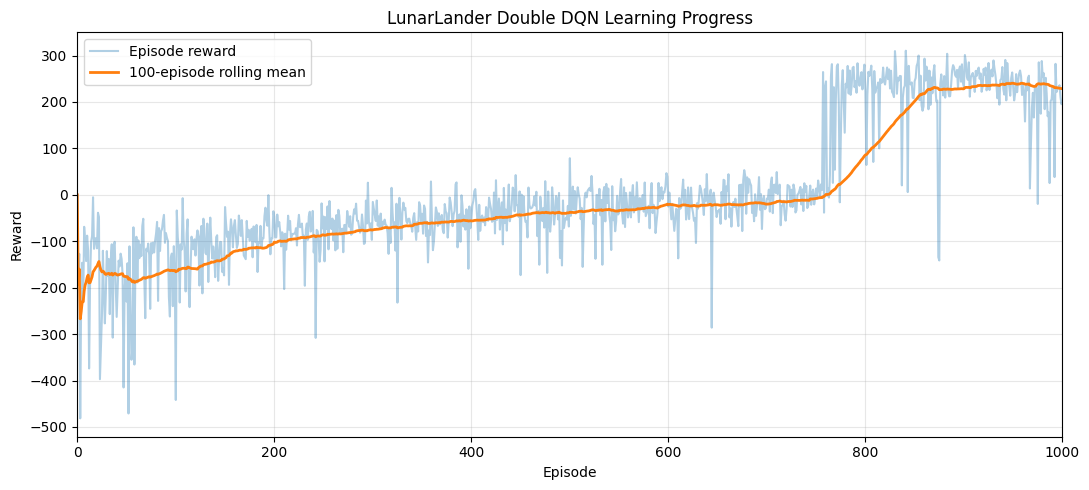

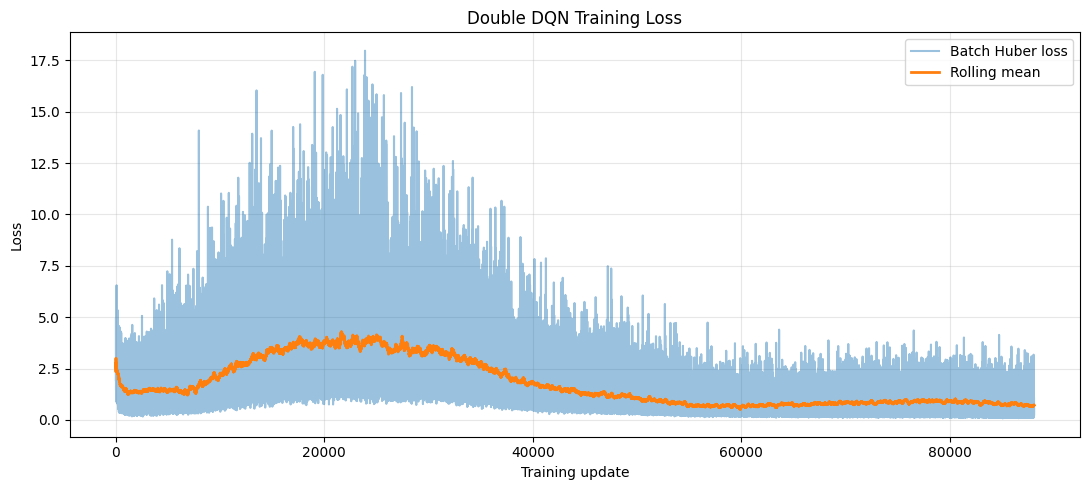

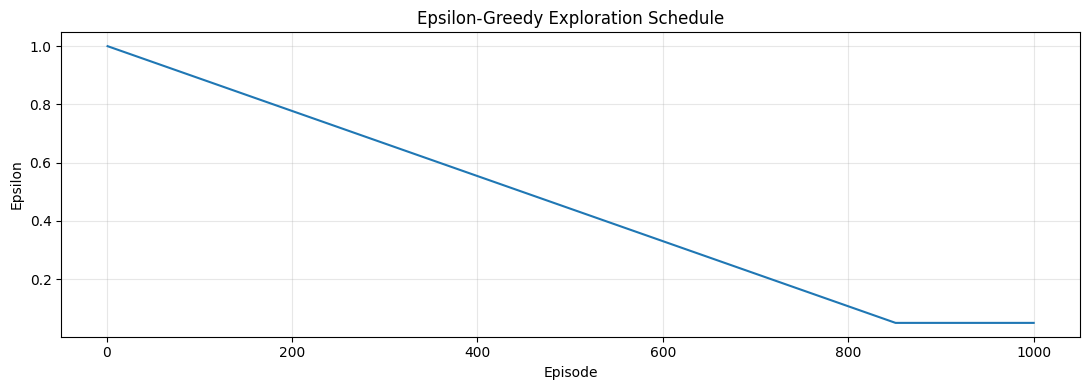

{'rewards': PosixPath('outputs/lunar_rewards.png'),
 'loss': PosixPath('outputs/lunar_loss.png'),
 'epsilon': PosixPath('outputs/lunar_epsilon.png')}

In [8]:
def plot_training_curves(log_df: pd.DataFrame, losses: list[float], cfg: Config) -> dict[str, Path]:
    """Create and save reward, loss, and epsilon plots for the report."""
    plot_paths = {}

    rewards_path = cfg.output_dir / "lunar_rewards.png"
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot([0, *log_df["episode"]], [0.0, *log_df["reward"]], alpha=0.35, label="Episode reward")
    ax.plot(
        [0, *log_df["episode"]],
        [0.0, *log_df["rolling_reward"]],
        linewidth=2.0,
        label=f"{cfg.rolling_window}-episode rolling mean",
    )
    ax.set_xlim(0, cfg.episodes)
    ax.set_xlabel("Episode")
    ax.set_ylabel("Reward")
    ax.set_title("LunarLander Double DQN Learning Progress")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(rewards_path, dpi=160)
    plt.show()
    plot_paths["rewards"] = rewards_path

    loss_path = cfg.output_dir / "lunar_loss.png"
    fig, ax = plt.subplots(figsize=(11, 5))
    if losses:
        ax.plot(np.arange(1, len(losses) + 1), losses, alpha=0.45, label="Batch Huber loss")
        loss_smooth = pd.Series(losses).rolling(window=200, min_periods=1).mean()
        ax.plot(np.arange(1, len(loss_smooth) + 1), loss_smooth, linewidth=2.0, label="Rolling mean")
    else:
        ax.text(0.5, 0.5, "No loss values recorded", ha="center", va="center", transform=ax.transAxes)
    ax.set_xlabel("Training update")
    ax.set_ylabel("Loss")
    ax.set_title("Double DQN Training Loss")
    if losses:
        ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(loss_path, dpi=160)
    plt.show()
    plot_paths["loss"] = loss_path

    epsilon_path = cfg.output_dir / "lunar_epsilon.png"
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(log_df["episode"], log_df["epsilon"])
    ax.set_xlabel("Episode")
    ax.set_ylabel("Epsilon")
    ax.set_title("Epsilon-Greedy Exploration Schedule")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(epsilon_path, dpi=160)
    plt.show()
    plot_paths["epsilon"] = epsilon_path
    return plot_paths


plot_paths = plot_training_curves(training_log, training_losses, cfg)
plot_paths

## Greedy Evaluation

Evaluation uses epsilon `0.0`, so the learned policy exploits the Q-network greedily rather than
exploring.

In [9]:
def evaluate(agent: DoubleDQNAgent, cfg: Config, episodes: int = 10) -> dict:
    """Evaluate the greedy policy with epsilon fixed at zero."""
    env, env_id = make_lunar_env(seed=cfg.seed + 10_000)
    eval_rewards = []
    eval_lengths = []
    final_x_positions = []
    final_angles = []
    successful_centered_landings = 0
    for episode in range(episodes):
        state, _ = env.reset(seed=cfg.seed + 10_000 + episode)
        total_reward = 0.0
        final_state = state
        for step in range(1, cfg.max_steps_per_episode + 1):
            action = agent.act(state, epsilon=0.0)
            state, reward, terminated, truncated, _ = env.step(action)
            final_state = state
            total_reward += float(reward)
            if terminated or truncated:
                break
        both_legs = bool(final_state[6]) and bool(final_state[7])
        centered = abs(float(final_state[0])) < cfg.shaping_center_threshold
        if both_legs and centered:
            successful_centered_landings += 1
        eval_rewards.append(total_reward)
        eval_lengths.append(step)
        final_x_positions.append(float(final_state[0]))
        final_angles.append(float(final_state[4]))
    env.close()
    result = {
        "env_id": env_id,
        "episodes": episodes,
        "mean_reward": float(np.mean(eval_rewards)),
        "std_reward": float(np.std(eval_rewards)),
        "min_reward": float(np.min(eval_rewards)),
        "max_reward": float(np.max(eval_rewards)),
        "mean_length": float(np.mean(eval_lengths)),
        "mean_abs_final_x": float(np.mean(np.abs(final_x_positions))),
        "centered_landing_rate": float(successful_centered_landings / episodes),
        "rewards": eval_rewards,
        "lengths": eval_lengths,
        "final_x_positions": final_x_positions,
        "final_angles": final_angles,
    }
    eval_path = cfg.output_dir / "lunar_evaluation.json"
    eval_path.write_text(json.dumps(result, indent=2))
    print(f"Saved evaluation results to {eval_path}")
    return result


evaluation_result = evaluate(agent, cfg, episodes=cfg.eval_episodes)
evaluation_result

Saved evaluation results to outputs/lunar_evaluation.json


{'env_id': 'LunarLander-v3',
 'episodes': 10,
 'mean_reward': 283.56484403195094,
 'std_reward': 12.06780585899103,
 'min_reward': 254.9006929711685,
 'max_reward': 297.04207806977047,
 'mean_length': 254.4,
 'mean_abs_final_x': 0.02896250644698739,
 'centered_landing_rate': 0.9,
 'rewards': [274.67947926439837,
  280.14288131928254,
  254.9006929711685,
  282.23197087210815,
  277.9604029627948,
  297.04207806977047,
  295.44144336875326,
  287.7757592492924,
  293.7777180707552,
  291.6960141711856],
 'lengths': [258, 315, 216, 293, 274, 216, 230, 255, 241, 246],
 'final_x_positions': [-0.013051891699433327,
  0.027977656573057175,
  -0.010315609164536,
  0.027339553460478783,
  0.012040329165756702,
  -0.12863120436668396,
  -0.010825062170624733,
  -0.008345698937773705,
  -0.03570546954870224,
  0.015392589382827282],
 'final_angles': [-0.0004324557085055858,
  -0.0019483427749946713,
  -0.0021154452115297318,
  -0.0014294686261564493,
  -0.0013732019579038024,
  -0.02610697224736

## Demonstration GIF

The GIF is generated from a fresh `render_mode="rgb_array"` environment. To avoid showing an unlucky
but valid rollout, the helper first scores several deterministic greedy rollouts without rendering,
prefers centred and shorter successful landings, then renders the selected seed once.

In [10]:
def rollout_demo_candidate(agent: DoubleDQNAgent, cfg: Config, seed: int) -> dict:
    """Run one non-rendered greedy rollout and score it for demo suitability."""
    env, env_id = make_lunar_env(seed=seed)
    state, _ = env.reset(seed=seed)
    total_reward = 0.0
    first_contact_step = None
    final_state = state
    terminated = False
    truncated = False

    for step in range(1, cfg.demo_max_steps + 1):
        action = agent.act(state, epsilon=0.0)
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += float(reward)
        if first_contact_step is None and (next_state[6] > 0 or next_state[7] > 0):
            first_contact_step = step
        state = next_state
        final_state = next_state
        if terminated or truncated:
            break
    env.close()

    both_legs = bool(final_state[6]) and bool(final_state[7])
    centered_bonus = cfg.demo_success_bonus if both_legs else 0.0
    score = (
        total_reward
        - cfg.demo_center_weight * abs(float(final_state[0]))
        - cfg.demo_step_weight * step
        + centered_bonus
    )
    return {
        "seed": seed,
        "env_id": env_id,
        "reward": float(total_reward),
        "steps": int(step),
        "final_x": float(final_state[0]),
        "final_y": float(final_state[1]),
        "final_vx": float(final_state[2]),
        "final_vy": float(final_state[3]),
        "final_angle": float(final_state[4]),
        "both_legs": both_legs,
        "first_contact_step": first_contact_step,
        "terminated": bool(terminated),
        "truncated": bool(truncated),
        "selection_score": float(score),
    }


def render_demo_for_seed(agent: DoubleDQNAgent, cfg: Config, seed: int) -> tuple[list[np.ndarray], float]:
    """Render a single selected greedy rollout as RGB frames."""
    env, _ = make_lunar_env(render_mode="rgb_array", seed=seed)
    frames = []
    state, _ = env.reset(seed=seed)
    total_reward = 0.0
    for _ in range(cfg.demo_max_steps):
        frame = env.render()
        if frame is not None:
            frames.append(frame)
        action = agent.act(state, epsilon=0.0)
        state, reward, terminated, truncated, _ = env.step(action)
        total_reward += float(reward)
        if terminated or truncated:
            frame = env.render()
            if frame is not None:
                frames.append(frame)
            break
    env.close()
    return frames, total_reward


def generate_demo(agent: DoubleDQNAgent, cfg: Config) -> Path | list[Path]:
    """Select a clean greedy landing and save it as a GIF, falling back to PNG frames."""
    candidates = [
        rollout_demo_candidate(agent, cfg, cfg.seed + cfg.demo_seed_offset + idx)
        for idx in range(cfg.demo_candidate_count)
    ]
    best = max(candidates, key=lambda item: item["selection_score"])
    demo_metadata_path = cfg.output_dir / "lunar_demo_selection.json"
    demo_metadata_path.write_text(json.dumps({"selected": best, "candidates": candidates}, indent=2))

    frames, total_reward = render_demo_for_seed(agent, cfg, best["seed"])
    gif_path = cfg.video_dir / "lunar_lander_trained_agent.gif"
    if frames:
        try:
            imageio.mimsave(gif_path, frames, fps=cfg.gif_fps)
            print(
                f"Saved GIF to {gif_path}; seed={best['seed']}; "
                f"reward={total_reward:.1f}; final_x={best['final_x']:.3f}; steps={best['steps']}"
            )
            print(f"Saved demo selection metadata to {demo_metadata_path}")
            return gif_path
        except Exception as exc:
            print(f"GIF creation failed: {exc}")

    fallback_paths = []
    for idx, frame in enumerate(frames[:8]):
        frame_path = cfg.video_dir / f"lunar_lander_demo_frame_{idx:02d}.png"
        imageio.imwrite(frame_path, frame)
        fallback_paths.append(frame_path)
    print(f"Saved fallback frames: {fallback_paths}")
    return fallback_paths


demo_output = generate_demo(agent, cfg)
demo_output

Saved GIF to videos/lunar_lander_trained_agent.gif; seed=20547; reward=306.5; final_x=0.026; steps=297
Saved demo selection metadata to outputs/lunar_demo_selection.json


PosixPath('videos/lunar_lander_trained_agent.gif')

## Final Summary

In [11]:
summary = {
    "environment": active_env_id,
    "episodes": cfg.episodes,
    "reward_plot": str(plot_paths["rewards"]),
    "loss_plot": str(plot_paths["loss"]),
    "epsilon_plot": str(plot_paths["epsilon"]),
    "checkpoint": str(checkpoint_path),
    "evaluation_mean_reward": evaluation_result["mean_reward"],
    "evaluation_std_reward": evaluation_result["std_reward"],
    "demo_output": str(demo_output),
}
summary

{'environment': 'LunarLander-v3',
 'episodes': 1000,
 'reward_plot': 'outputs/lunar_rewards.png',
 'loss_plot': 'outputs/lunar_loss.png',
 'epsilon_plot': 'outputs/lunar_epsilon.png',
 'checkpoint': 'models/lunar_double_dqn_checkpoint.pt',
 'evaluation_mean_reward': 283.56484403195094,
 'evaluation_std_reward': 12.06780585899103,
 'demo_output': 'videos/lunar_lander_trained_agent.gif'}